# AI512 Project: UltraLight VM-UNet on TN3K Thyroid Ultrasound
## Lesion-Scale-Aware Boundary Preservation under Speckle Corruption

This notebook automates the training, evaluation, and complete report deliverables across all 4 experiments:
- **E1**: Original UltraLight VM-UNet Baseline Reproduction
- **E2**: Baseline + Lesion-Scale-Aware Boundary Supervision
- **E3**: Baseline + Corruption-Aware Consistency Training
- **E4**: Full Combined Proposed Framework

> **Smart Checkpointing**: If an experiment is already trained, it is automatically detected and skipped to save time. Set `FORCE_RETRAIN = True` only when you want to retrain from scratch.

### 1. Hardware & GPU Check

In [ ]:
!nvidia-smi

### 2. Fast Dependency Installation (Under 20 Seconds)

In [1]:
!pip install -q pyyaml scipy scikit-image timm thop pandas matplotlib
print("✅ Core dependencies ready!")

✅ Core dependencies ready!


### 3. Sync Latest Code from GitHub

In [2]:
import os

REPO_URL = "https://github.com/YeswanthTejaJakka/ML_UVnet_Project.git"

if not os.path.exists('/content/ML_UVnet'):
    !git clone $REPO_URL /content/ML_UVnet
else:
    %cd /content/ML_UVnet
    !git pull

%cd /content/ML_UVnet

# Verify UltraLight VM-UNet forward pass
import torch
from models import UltraLight_VM_UNet
test_model = UltraLight_VM_UNet().cuda()
dummy = torch.randn(1, 3, 256, 256).cuda()
with torch.no_grad():
    out = test_model(dummy)
print(f"\n✅ SUCCESS: UltraLight VM-UNet verified! Parameters: {sum(p.numel() for p in test_model.parameters()) / 1e6:.4f}M")

Cloning into '/content/ML_UVnet'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 48 (delta 15), reused 44 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 47.94 KiB | 4.36 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/ML_UVnet

✅ SUCCESS: UltraLight VM-UNet verified! Parameters: 0.0495M


### 4. Mount Google Drive and Unpack TN3K Dataset Locally
Unpacks `TN3K.zip` to Colab NVMe scratch disk `/content/tn3k` in under 15 seconds.

In [3]:
import shutil
from google.colab import drive
drive.mount('/content/drive')

drive_zip = '/content/drive/MyDrive/TN3K.zip'
drive_folder = '/content/drive/MyDrive/TN3K_extracted/Thyroid Dataset/tn3k'
local_dir = '/content/tn3k'

if not os.path.exists(local_dir):
    if os.path.exists(drive_zip):
        print("Copying TN3K.zip to local /content/...")
        shutil.copy(drive_zip, '/content/TN3K.zip')
        print("Unzipping...")
        !unzip -q /content/TN3K.zip -d /content/
        if not os.path.exists(local_dir) and os.path.exists('/content/Thyroid Dataset/tn3k'):
            !mv "/content/Thyroid Dataset/tn3k" /content/tn3k
        elif not os.path.exists(local_dir) and os.path.exists('/content/TN3K'):
            !mv /content/TN3K /content/tn3k
    elif os.path.exists(drive_folder):
        print("Copying extracted folder from Drive...")
        !cp -r "$drive_folder" /content/tn3k

print("\n--- Dataset Verification ---")
print("TrainVal Images:", len(os.listdir('/content/tn3k/trainval-image')))
print("Test Images:    ", len(os.listdir('/content/tn3k/test-image')))
print("Dataset ready at /content/tn3k")

Mounted at /content/drive
Copying TN3K.zip to local /content/...
Unzipping...

--- Dataset Verification ---
TrainVal Images: 2879
Test Images:     614
Dataset ready at /content/tn3k


### 5. Experiment 1 (E1): UltraLight VM-UNet Baseline Reproduction
\/

In [ ]:
%cd /content/ML_UVnet

# Set to True ONLY if you want to retrain from scratch
FORCE_RETRAIN_E1 = False
flag = "--force_retrain" if FORCE_RETRAIN_E1 else ""

!python train.py --config configs/e1_baseline.yaml \
                 --data_root /content/tn3k \
                 --fold 0 \
                 --epochs 50 \
                 --batch_size 16 \
                 --save_dir /content/drive/MyDrive/ML_UVnet_checkpoints/e1_baseline $flag

### 6. Experiment 2 (E2): Lesion-Scale-Aware Boundary Supervision

In [ ]:
%cd /content/ML_UVnet

# Set to True ONLY if you want to retrain from scratch
FORCE_RETRAIN_E2 = False
flag = "--force_retrain" if FORCE_RETRAIN_E2 else ""

!python train.py --config configs/e2_boundary.yaml \
                 --data_root /content/tn3k \
                 --fold 0 \
                 --epochs 50 \
                 --batch_size 16 \
                 --save_dir /content/drive/MyDrive/ML_UVnet_checkpoints/e2_boundary $flag

### 7. Experiment 3 (E3): Corruption-Aware Consistency Training
completed training of 50 epochs and saved

In [4]:
%cd /content/ML_UVnet

# Set to True ONLY if you want to retrain from scratch
FORCE_RETRAIN_E3 = False
flag = "--force_retrain" if FORCE_RETRAIN_E3 else ""

!python train.py --config configs/e3_consistency.yaml \
                 --data_root /content/tn3k \
                 --fold 0 \
                 --epochs 50 \
                 --batch_size 16 \
                 --save_dir /content/drive/MyDrive/ML_UVnet_checkpoints/e3_consistency $flag

/content/ML_UVnet
=== Experiment: e3_consistency on cuda ===
Dataset root: /content/tn3k | Fold: 0
⚠️ Created safety backup of previous model weights: /content/drive/MyDrive/ML_UVnet_checkpoints/e3_consistency/best_model_backup_20261105_105601.pth
Train samples: 1503 | Val samples: 376
Model initialized: 0.0495M parameters
Epoch [001/050] Loss: 1.1295 (Seg: 1.1268, Bnd: 0.0000, Cons: 0.0027) | Val Dice: 0.4279 | Val IoU: 0.2977 | LR: 0.000999
  --> Saved new best model checkpoint! Best Val Dice: 0.4279
Epoch [002/050] Loss: 0.9486 (Seg: 0.9442, Bnd: 0.0000, Cons: 0.0044) | Val Dice: 0.4539 | Val IoU: 0.3160 | LR: 0.000996
  --> Saved new best model checkpoint! Best Val Dice: 0.4539
Epoch [003/050] Loss: 0.8866 (Seg: 0.8821, Bnd: 0.0000, Cons: 0.0045) | Val Dice: 0.4528 | Val IoU: 0.3204 | LR: 0.000991
Epoch [004/050] Loss: 0.8470 (Seg: 0.8433, Bnd: 0.0000, Cons: 0.0038) | Val Dice: 0.5117 | Val IoU: 0.3741 | LR: 0.000984
  --> Saved new best model checkpoint! Best Val Dice: 0.5117
Epoc

### 8. Experiment 4 (E4): Full Combined Proposed Framework

In [5]:
%cd /content/ML_UVnet

# Set to True ONLY if you want to retrain from scratch
FORCE_RETRAIN_E4 = True
flag = "--force_retrain" if FORCE_RETRAIN_E4 else ""

!python train.py --config configs/e4_combined.yaml \
                 --data_root /content/tn3k \
                 --fold 0 \
                 --epochs 50 \
                 --batch_size 16 \
                 --save_dir /content/drive/MyDrive/ML_UVnet_checkpoints/e4_combined $flag

/content/ML_UVnet
=== Experiment: e4_combined on cuda ===
Dataset root: /content/tn3k | Fold: 0
⚠️ Created safety backup of previous model weights: /content/drive/MyDrive/ML_UVnet_checkpoints/e4_combined/best_model_backup_20261105_114629.pth
Train samples: 1503 | Val samples: 376
Model initialized: 0.0495M parameters
Epoch [001/050] Loss: 3.1518 (Seg: 1.2563, Bnd: 1.8887, Cons: 0.0068) | Val Dice: 0.3522 | Val IoU: 0.2307 | LR: 0.000999
  --> Saved new best model checkpoint! Best Val Dice: 0.3522
Epoch [002/050] Loss: 2.2137 (Seg: 1.0258, Bnd: 1.1840, Cons: 0.0040) | Val Dice: 0.3733 | Val IoU: 0.2474 | LR: 0.000996
  --> Saved new best model checkpoint! Best Val Dice: 0.3733
Epoch [003/050] Loss: 2.1093 (Seg: 0.9415, Bnd: 1.1646, Cons: 0.0033) | Val Dice: 0.4659 | Val IoU: 0.3307 | LR: 0.000991
  --> Saved new best model checkpoint! Best Val Dice: 0.4659
Epoch [004/050] Loss: 2.0389 (Seg: 0.8860, Bnd: 1.1496, Cons: 0.0032) | Val Dice: 0.4955 | Val IoU: 0.3548 | LR: 0.000984
  --> Save

## 📊 DELIVERABLES GENERATION
Executes the full benchmark evaluation on the held-out test set and generates all 8 course deliverables.

In [6]:
%cd /content/ML_UVnet
!python generate_deliverables.py --checkpoints_root /content/drive/MyDrive/ML_UVnet_checkpoints \
                                --data_root /content/tn3k \
                                --output_dir /content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables

/content/ML_UVnet
      AI512 RESEARCH PROJECT - FULL DELIVERABLES GENERATOR        
Checkpoints Root: /content/drive/MyDrive/ML_UVnet_checkpoints
Dataset Root:     /content/tn3k
Output Directory: /content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables
Evaluation Device:cuda

✅ Loaded E1_Baseline from: /content/drive/MyDrive/ML_UVnet_checkpoints/e1_baseline/best_model.pth
✅ Loaded E2_Boundary from: /content/drive/MyDrive/ML_UVnet_checkpoints/e2_boundary/best_model.pth
✅ Loaded E3_Consistency from: /content/drive/MyDrive/ML_UVnet_checkpoints/e3_consistency/best_model.pth
✅ Loaded E4_Combined from: /content/drive/MyDrive/ML_UVnet_checkpoints/e4_combined/best_model.pth

Loaded official held-out test set: 614 images.

--> Generating Deliverable 1: Training Curves...
    Saved: /content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/training_curves_E1_E4.png
--> Running Inference on Held-Out Test Set...
--> Generating Deliverable 2: Final Test Comparison Table...
    Saved: /c

### Deliverable 1: Training Loss & Validation Dice Curves (E1 to E4)

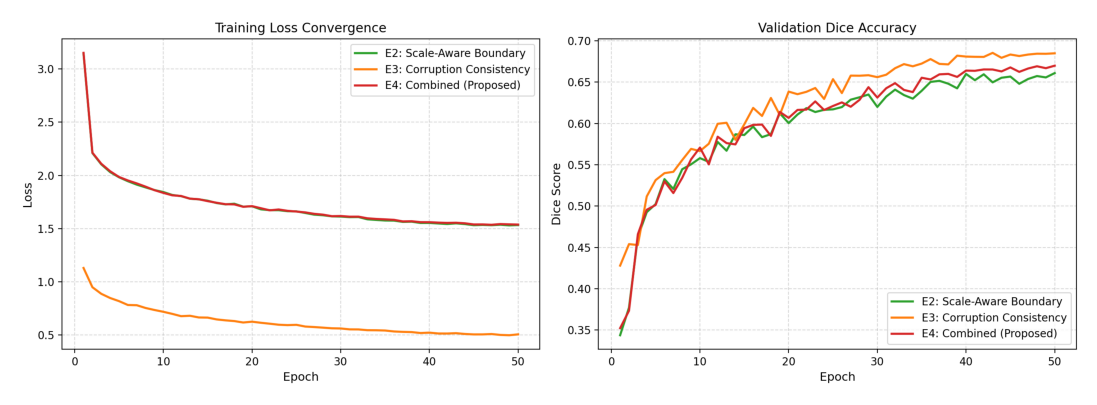

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

img_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/training_curves_E1_E4.png'
if os.path.exists(img_path):
    plt.figure(figsize=(14, 5))
    plt.imshow(Image.open(img_path))
    plt.axis('off')
    plt.show()

### Deliverable 2: Final Test Comparison Table (E1 vs E2 vs E3 vs E4)

In [8]:
import pandas as pd
csv_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/final_test_comparison.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    display(df)

,Model,Dice,IoU,Precision,Recall
0,E1_Baseline,0.5784,0.4406,0.6201,0.6920
1,E2_Boundary,0.6712,0.5453,0.6934,0.7519
2,E3_Consistency,0.6851,0.5570,0.7067,0.7650
3,E4_Combined,0.6671,0.5415,0.6911,0.7482


### Deliverable 3: Lesion-Scale Stratification (Small vs Medium vs Large Nodules)

In [9]:
csv_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/lesion_size_evaluation.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    display(df)

,Model,Lesion_Category,Count,Dice,IoU
0,E1_Baseline,Small,127,0.3815,0.2595
1,E1_Baseline,Medium,242,0.5997,0.4537
2,E1_Baseline,Large,245,0.6593,0.5216
3,E2_Boundary,Small,127,0.4701,0.3425
4,E2_Boundary,Medium,242,0.6942,0.5644
5,E2_Boundary,Large,245,0.7528,0.6316
6,E3_Consistency,Small,127,0.4939,0.3635
7,E3_Consistency,Medium,242,0.7011,0.5678
8,E3_Consistency,Large,245,0.7684,0.6465
9,E4_Combined,Small,127,0.4625,0.3343


### Deliverable 4: Boundary Preservation Metrics (Boundary IoU & HD95)

In [10]:
csv_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/boundary_metrics_summary.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    display(df)

,Model,Boundary_IoU,HD95_Pixels
0,E1_Baseline,0.0317,35.32
1,E2_Boundary,0.0503,26.04
2,E3_Consistency,0.0512,25.31
3,E4_Combined,0.0511,27.08


### Deliverable 5: Ultrasound Speckle Noise Degradation Benchmark

,Speckle_Sigma,E1_Baseline_Dice,E2_Boundary_Dice,E3_Consistency_Dice,E4_Combined_Dice
0,0.00,0.5784,0.6712,0.6851,0.6671
1,0.05,0.5760,0.6692,0.6828,0.6666
2,0.10,0.5664,0.6535,0.6797,0.6651
3,0.15,0.5523,0.6273,0.6730,0.6600
4,0.20,0.5239,0.5921,0.6646,0.6574
5,0.25,0.4981,0.5506,0.6517,0.6485


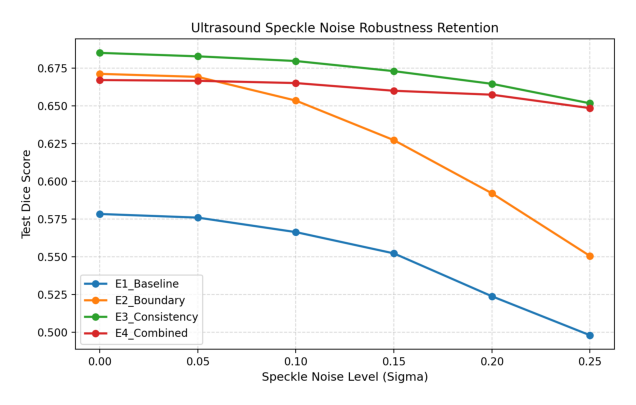

In [11]:
csv_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/robustness_per_condition.csv'
png_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/speckle_robustness_curve.png'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    display(df)
if os.path.exists(png_path):
    plt.figure(figsize=(9, 5))
    plt.imshow(Image.open(png_path))
    plt.axis('off')
    plt.show()

### Deliverable 6: Model Efficiency & Latency Benchmark

In [12]:
csv_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/efficiency_results.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    display(df)

,Model,Parameters_M,FLOPs_G,Latency_ms,FPS
0,E1_Baseline,0.0495,0.0666,58.88,17.0
1,E2_Boundary,0.0495,0.0666,53.57,18.7
2,E3_Consistency,0.0495,0.0666,56.53,17.7
3,E4_Combined,0.0495,0.0666,50.91,19.6


### Deliverable 7: Qualitative Side-by-Side Visual Comparison (8 Test Cases)

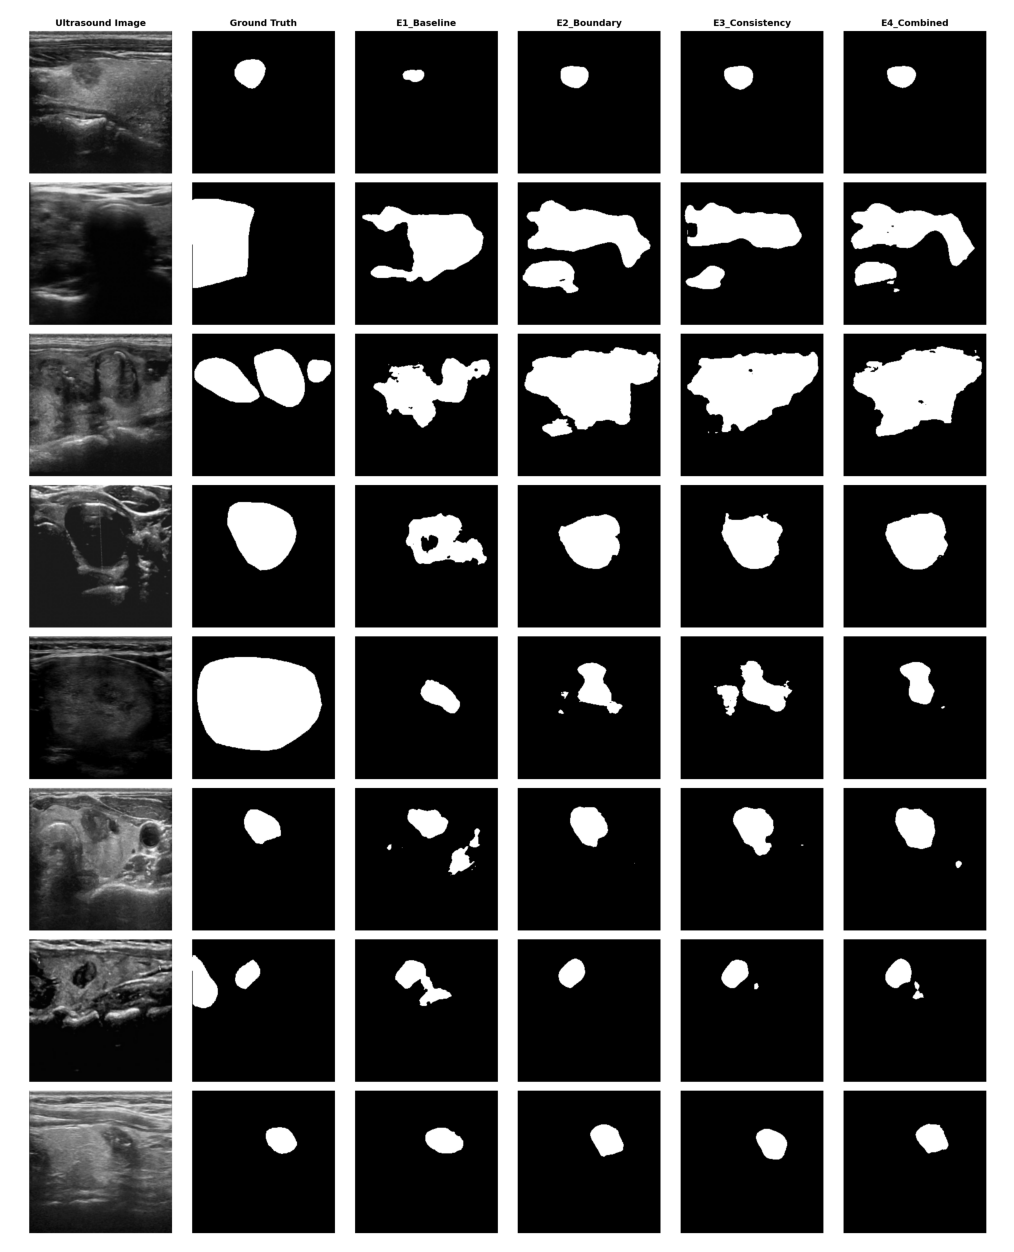

In [13]:
png_path = '/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables/qualitative_comparison_8_cases.png'
if os.path.exists(png_path):
    plt.figure(figsize=(18, 16))
    plt.imshow(Image.open(png_path))
    plt.axis('off')
    plt.show()

### Deliverable 8: Final Report Asset Checklist Verification

In [14]:
from pathlib import Path

root = Path('/content/drive/MyDrive/ML_UVnet_checkpoints/final_deliverables')
files_to_check = [
    'final_test_comparison.csv',
    'lesion_size_evaluation.csv',
    'boundary_metrics_summary.csv',
    'robustness_per_condition.csv',
    'speckle_robustness_curve.png',
    'efficiency_results.csv',
    'training_curves_E1_E4.png',
    'qualitative_comparison_8_cases.png',
]

print("====================================================")
print("           AI512 REPORT ASSET VERIFICATION          ")
print("====================================================")
all_passed = True
for name in files_to_check:
    p = root / name
    found = p.exists() and p.stat().st_size > 0
    status = "✅ FOUND" if found else "❌ MISSING"
    print(f"{status:10} | {name}")
    if not found:
        all_passed = False

print("----------------------------------------------------")
if all_passed:
    print("🎉 ALL DELIVERABLES SUCCESSFULLY GENERATED AND SAVED!")
else:
    print("⚠️ Some deliverables are missing. Please complete all experiments.")
print("====================================================")

           AI512 REPORT ASSET VERIFICATION          
✅ FOUND    | final_test_comparison.csv
✅ FOUND    | lesion_size_evaluation.csv
✅ FOUND    | boundary_metrics_summary.csv
✅ FOUND    | robustness_per_condition.csv
✅ FOUND    | speckle_robustness_curve.png
✅ FOUND    | efficiency_results.csv
✅ FOUND    | training_curves_E1_E4.png
✅ FOUND    | qualitative_comparison_8_cases.png
----------------------------------------------------
🎉 ALL DELIVERABLES SUCCESSFULLY GENERATED AND SAVED!
